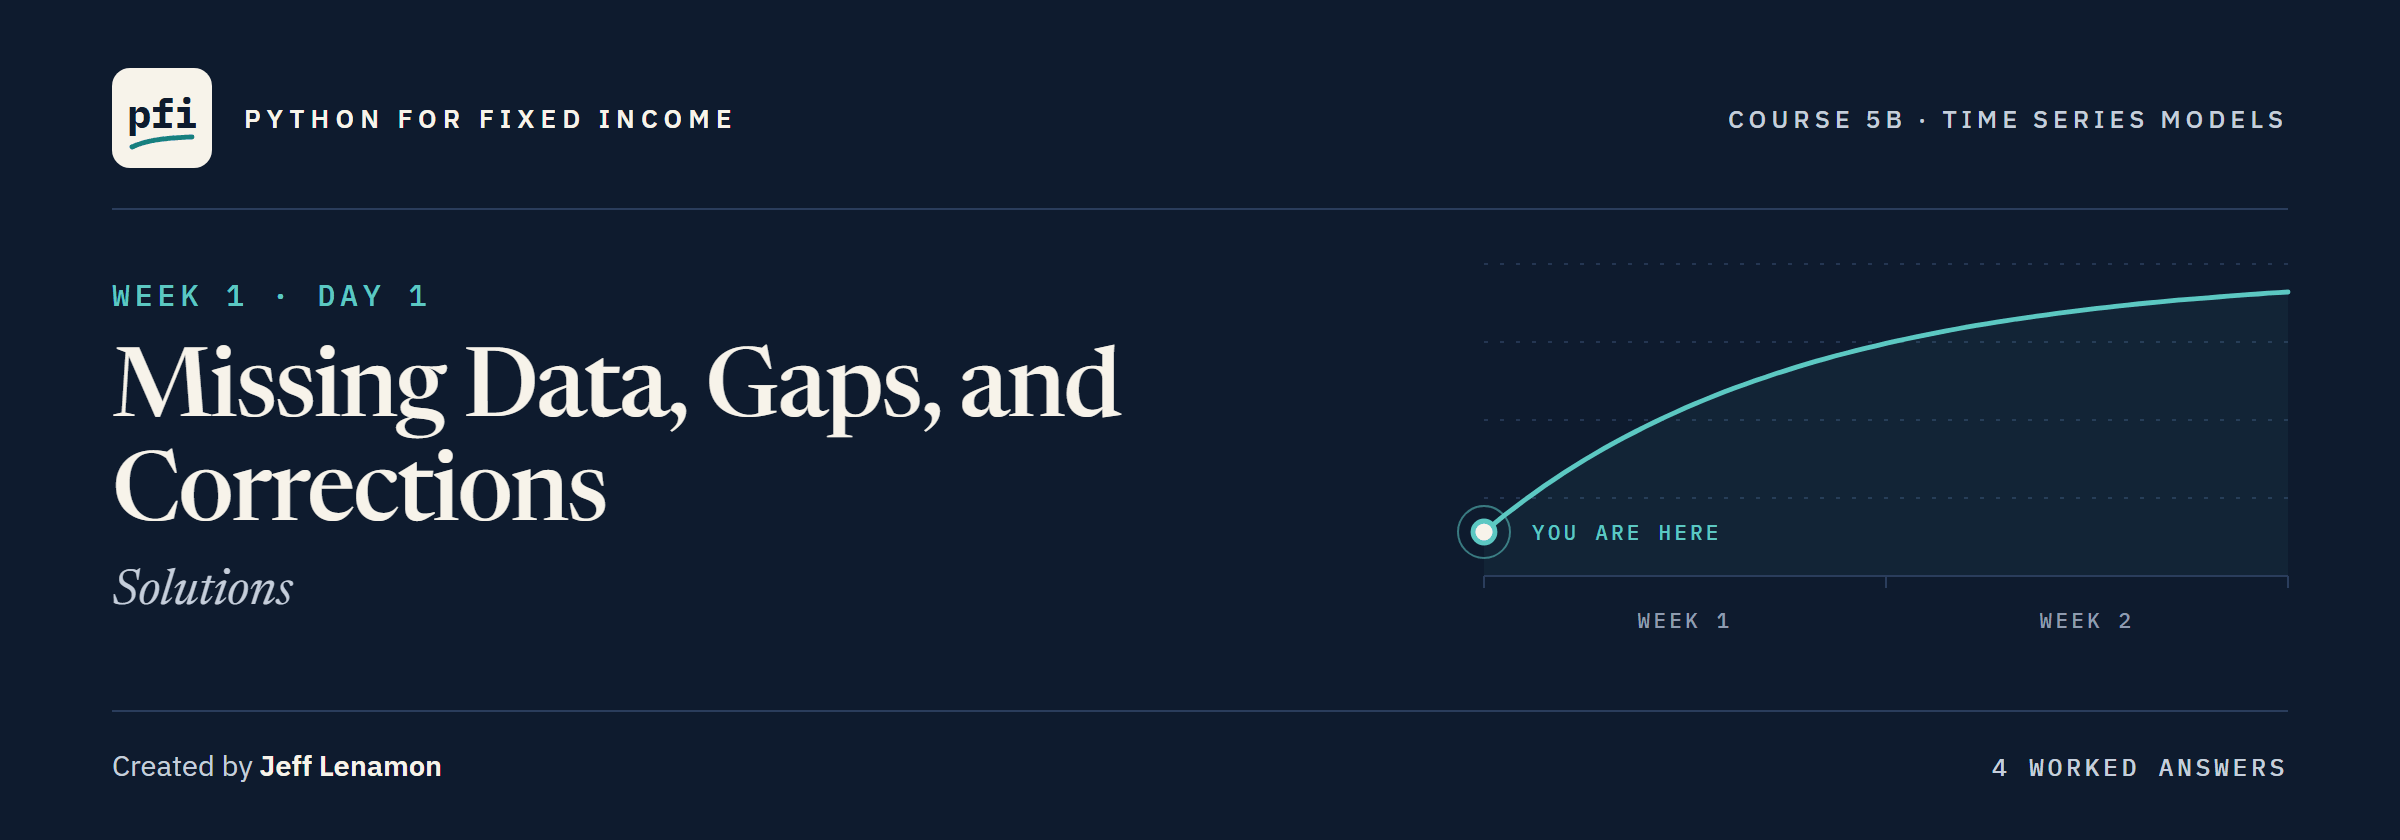

# Missing Data, Gaps, and Corrections: Solutions

Week 1, Day 1. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week1/day1/01_missing_data_gaps_and_corrections_solutions.ipynb)

# Problem Statement

## Business Context

Every model in this course reads one daily file: the U.S. Treasury's par yield curve, 14 tenors from 2015 to 2026.
A desk meets four kinds of trouble in such a file: market holidays, a feed outage, wrong prints, and series that start late.
The published file holds only the first and the last, so we plant the rest in a copy, from a seeded generator, and keep the true values aside.
We find, correct and fill each problem as if the copy had just arrived, and check every repair against the truth.
Today fits no model, so it works on the whole file.

## Objectives

Tell four kinds of missing apart, count each, and check the dated rows against a market calendar.
Find wrong values by their shape and by a second source, and correct them with a corrections table and a change log.
Find runs of blank cells, fill them with forward fill, backfill and interpolation, score each fill against held-back values, and cap how far a fill reaches.

## Data Dictionary

`treasury_par_yields.csv`, one row per market date:

1. `date`: the market date, the index
2. `1 Mo` to `30 Yr`: 14 par yields, in percent, shortest tenor first

Made in this notebook:

3. `planted`: a copy of the file with the planted problems
4. `backup`: a second source, the desk's own end-of-day sheet for the 2 Yr and the 10 Yr from 2021

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# the U.S. federal holiday calendar and Good Friday, as Course 3 used them
from pandas.tseries.holiday import USFederalHolidayCalendar, GoodFriday

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

# Loading the Data

## Reading the Treasury File

In [3]:
# the U.S. Treasury's daily par yields, in percent: one row per market date, one column per tenor
treasury = pd.read_csv(DATA + "treasury_par_yields.csv", parse_dates=["date"], index_col="date")
print(treasury.shape, "from", treasury.index[0].date(), "to", treasury.index[-1].date())

(2940, 14) from 2015-01-02 to 2026-10-02


2,940 market dates and 14 tenors.

`treasury` stays untouched from here on: it holds the true values.

## Planting the Problems

The four problems below are planted for the lesson, from one seeded generator, so every run plants the same ones.

In [4]:
# one seeded generator for every planted problem, and a copy to plant them in
rng = np.random.default_rng(SEED)
planted = treasury.copy()

# 1. an outage: 20 rows in a row, every tenor blank, starting somewhere in rows 1,100 to 1,399
outage_start = rng.integers(1_100, 1_400)
outage_dates = planted.index[outage_start:outage_start + 20]
planted.loc[outage_dates] = np.nan
print("outage:", outage_dates[0].date(), "to", outage_dates[-1].date())

outage: 2019-07-03 to 2019-07-31


In [5]:
# 2. single blank days: five rows in each tenor with a value on every date, away from the outage and the ends
full_tenors = [column for column in treasury.columns if treasury[column].notna().all()]
# np.r_ joins two ranges of row numbers into one array
away = np.r_[10:outage_start - 10, outage_start + 30:len(planted) - 10]
for column in full_tenors:
    rows = rng.choice(away, size=5, replace=False)
    planted.iloc[rows, planted.columns.get_loc(column)] = np.nan
print(len(full_tenors), "full tenors, 5 blank days in each")

11 full tenors, 5 blank days in each


In [6]:
# 3. three wrong prints, one date drawn in each year: np.flatnonzero gives the row numbers where a test is True
wrong_5y = planted.index[rng.choice(np.flatnonzero(planted.index.year == 2016))]
wrong_2y = planted.index[rng.choice(np.flatnonzero(planted.index.year == 2017))]
wrong_10y = planted.index[rng.choice(np.flatnonzero(planted.index.year == 2022))]
planted.loc[wrong_5y, "5 Yr"] = treasury.loc[wrong_5y, "30 Yr"]   # the 30 Yr's yield in the 5 Yr column
planted.loc[wrong_2y, "2 Yr"] = treasury.loc[wrong_2y, "2 Yr"] * 100   # a yield printed in bp
planted.loc[wrong_10y, "10 Yr"] = treasury.loc[wrong_10y, "10 Yr"] * 10   # a slipped decimal point
print("wrong prints:", wrong_5y.date(), wrong_2y.date(), wrong_10y.date())

wrong prints: 2016-10-31 2017-03-15 2022-10-20


In [7]:
# 4. a second source: the desk's own end-of-day sheet, kept for the 2 Yr and the 10 Yr from 2021
backup = treasury.loc["2021-01-04":, ["2 Yr", "10 Yr"]].copy()
print("second source:", backup.shape)

second source: (1439, 2)


An outage over July 2019, single blank days in 11 tenors, three wrong prints, and a second source of 1,439 dates.

In real work there is no `treasury` to check against, so the checks below are the ones a desk can run on what arrives.

**We work on `planted` as if it had just arrived, and read `treasury` only to score a repair.**

# Data Overview

## Checking the First Five Rows

In [8]:
planted.head()

,1 Mo,1.5 Month,2 Mo,3 Mo,4 Mo,6 Mo,1 Yr,2 Yr,3 Yr,5 Yr,7 Yr,10 Yr,20 Yr,30 Yr
date,,,,,,,,,,,,,,
2015-01-02,0.02,NaN,NaN,0.02,NaN,0.11,0.25,0.66,1.07,1.61,1.92,2.12,2.41,2.69
2015-01-05,0.02,NaN,NaN,0.03,NaN,0.10,0.26,0.68,1.06,1.57,1.85,2.04,2.32,2.60
2015-01-06,0.02,NaN,NaN,0.03,NaN,0.10,0.25,0.65,1.02,1.50,1.78,1.97,2.25,2.52
2015-01-07,0.02,NaN,NaN,0.03,NaN,0.09,0.25,0.62,1.00,1.47,1.76,1.96,2.25,2.52
2015-01-08,0.01,NaN,NaN,0.03,NaN,0.08,0.23,0.62,1.00,1.50,1.81,2.03,2.33,2.59


The `1.5 Month`, `2 Mo` and `4 Mo` columns are blank at the top of the file.

## Checking the Shape of the Data

In [9]:
planted.shape

(2940, 14)

2,940 rows by 14 tenors: 41,160 cells, each a value, a blank, or a wrong value.

![Seven rows of the planted copy with the columns date, 5 Yr, 10 Yr and 2 Mo. The 2 Mo is NaN on 2018-10-12 and 2018-10-15 and starts at 2.22 on 2018-10-16: not started yet. Every tenor is NaN on 2019-07-03 and 2019-07-05: blank cells, the row is there. A dashed line between those two dates marks 2019-07-04, which has no row at all: an absent row. On 2022-10-20 the 10 Yr reads 42.40 where the truth is 4.24: a wrong value](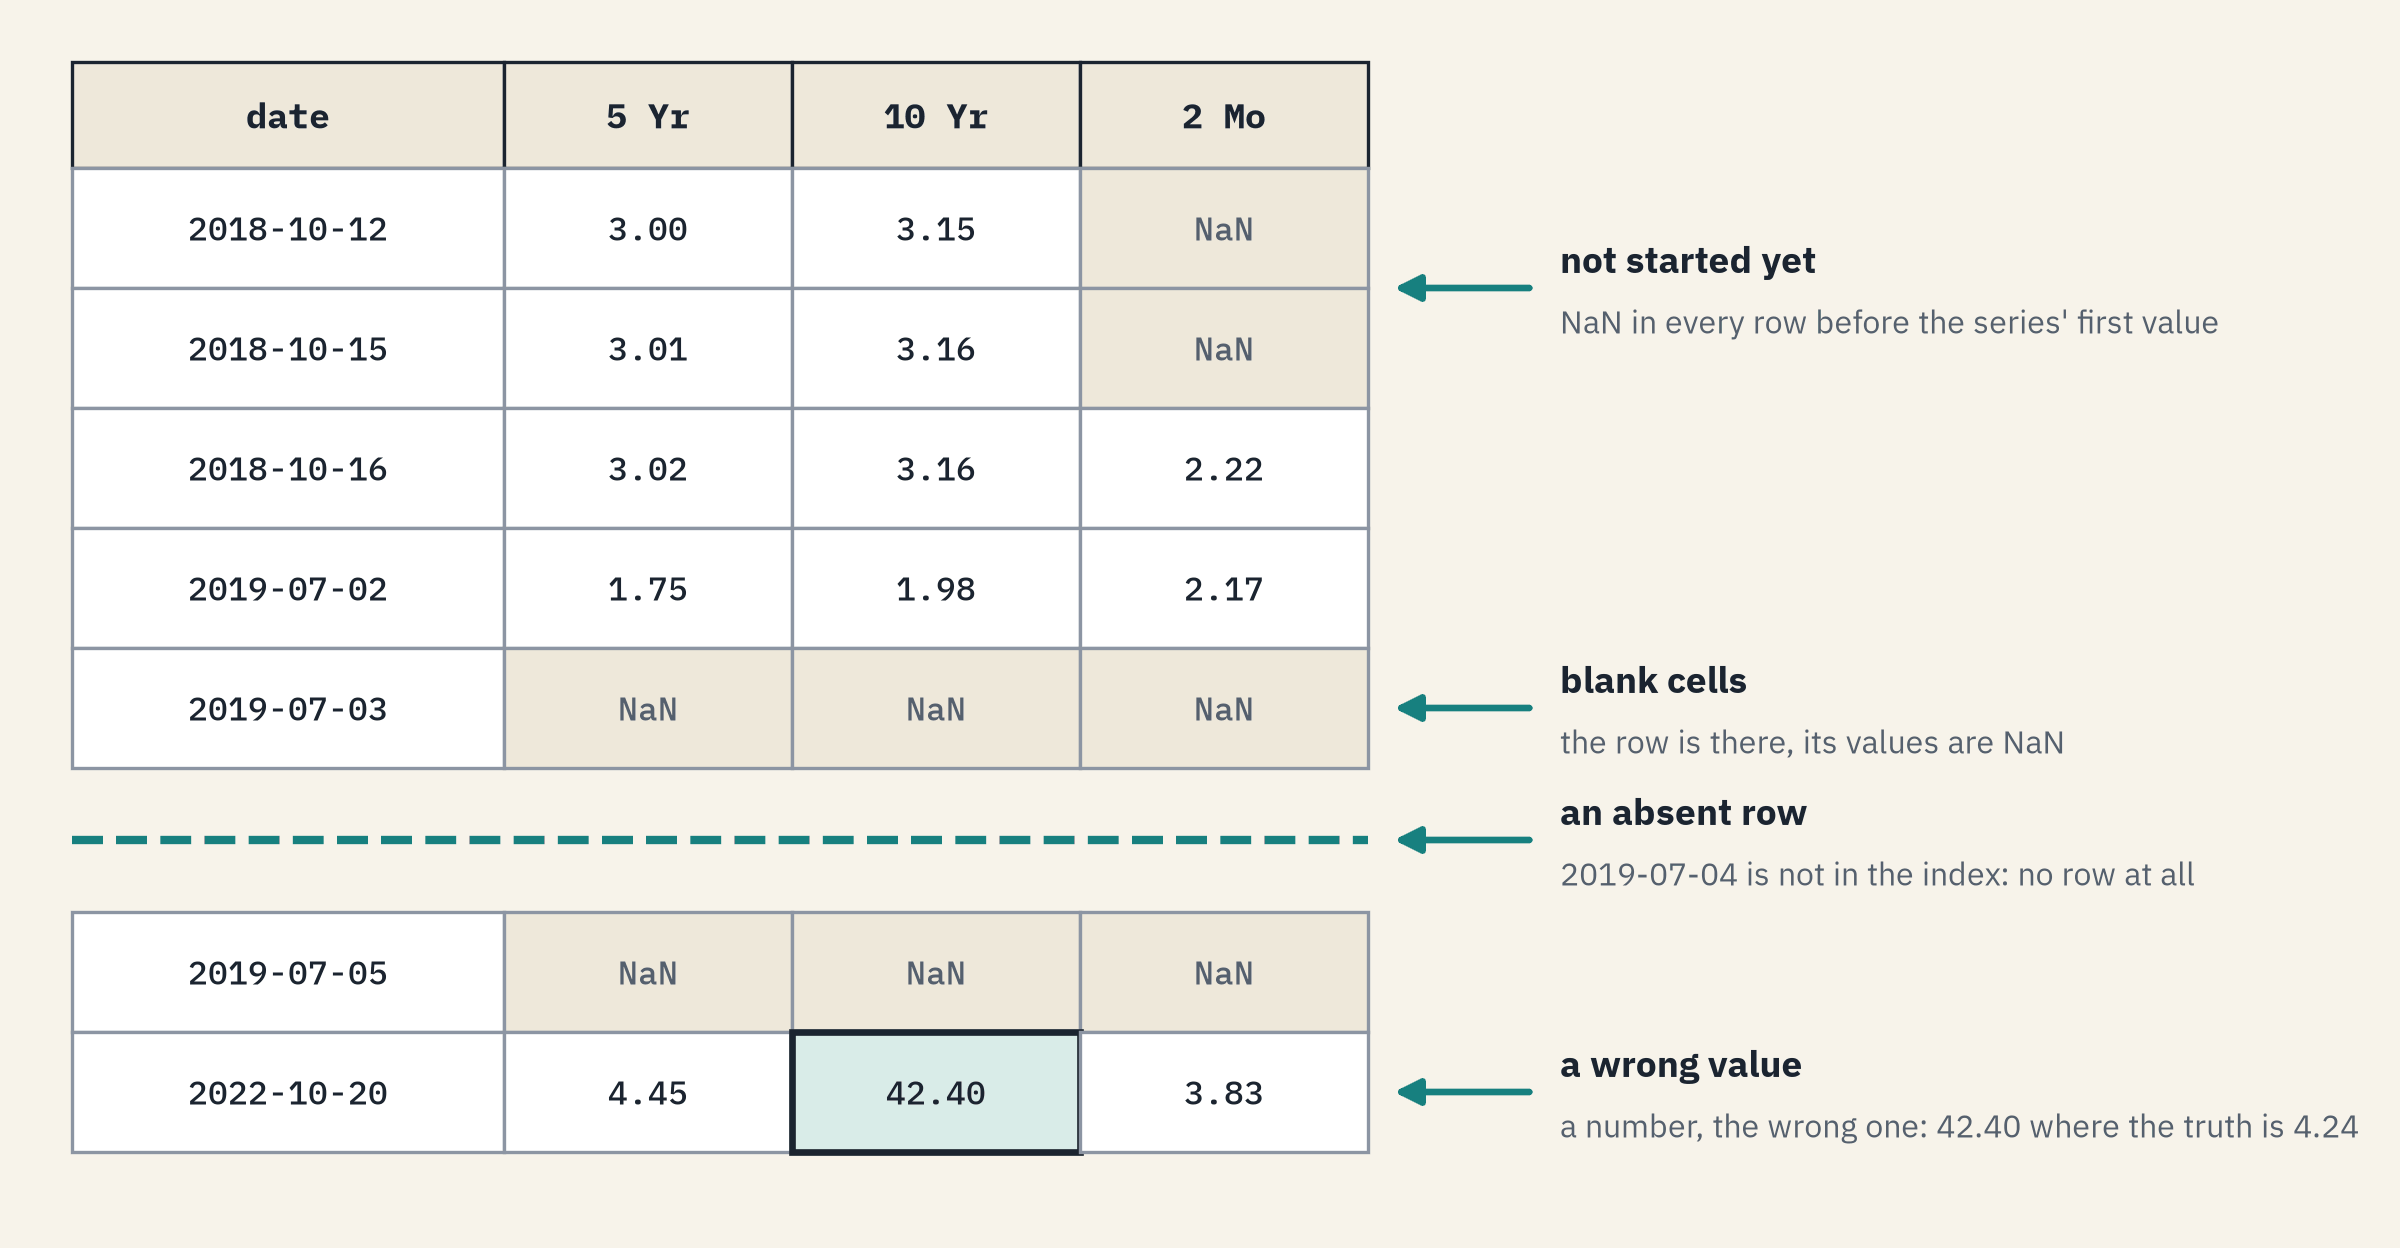)

A dated table can be missing a value in four ways, and each needs its own repair.

## Checking for Missing Values

In [10]:
# blank cells per tenor, in the published file and in the planted copy
blank_counts = pd.DataFrame({"published": treasury.isna().sum(), "planted": planted.isna().sum()})
blank_counts.T

,1 Mo,1.5 Month,2 Mo,3 Mo,4 Mo,6 Mo,1 Yr,2 Yr,3 Yr,5 Yr,7 Yr,10 Yr,20 Yr,30 Yr
published,0,2532,949,0,1951,0,0,0,0,0,0,0,0,0
planted,25,2532,969,25,1951,25,25,25,25,25,25,25,25,25


The published file's blanks are all in the three late tenors.

The copy adds 25 blanks to each full tenor and 20 to the `2 Mo`.

### Where Each Series Starts

In [11]:
# the first date with a value, for the three tenors with blanks at the top (Course 1's first_valid_index)
for column in ["2 Mo", "4 Mo", "1.5 Month"]:
    start = treasury[column].first_valid_index()
    print(column, "starts on", start.date(), "after", treasury.index.get_loc(start), "blank rows")

2 Mo starts on 2018-10-16 after 949 blank rows
4 Mo starts on 2022-10-19 after 1951 blank rows
1.5 Month starts on 2025-02-18 after 2532 blank rows


Each count matches the column's blanks in the published file.

A blank before a series starts is not a gap: there was nothing to miss.

## Checking the Statistical Summary

In [12]:
# four tenors of the planted copy
planted[["2 Yr", "5 Yr", "10 Yr", "30 Yr"]].describe().round(2)

,2 Yr,5 Yr,10 Yr,30 Yr
count,2915.00,2915.00,2915.00,2915.00
mean,2.33,2.48,2.78,3.22
std,2.91,1.33,1.40,1.07
min,0.09,0.19,0.52,0.99
25%,0.74,1.40,1.81,2.43
50%,2.12,2.28,2.51,3.01
75%,3.90,3.81,4.02,4.22
max,133.00,5.09,42.40,5.64


A 2 Yr maximum of 133.00 percent and a 10 Yr maximum of 42.40 percent are impossible yields.

The 5 Yr's maximum of 5.09 looks normal: a wrong print inside the usual range hides from a summary.

## Checking the Dates Against the Calendar

We repeat Course 3's notebook 03 check: the file's dates against every weekday and the holiday calendar.

In [13]:
# every weekday in the file's span, and the weekdays with no row
weekdays = pd.bdate_range(treasury.index[0], treasury.index[-1])
absent = weekdays.difference(treasury.index)
print(len(weekdays), "weekdays,", len(treasury), "rows,", len(absent), "weekdays with no row")

3066 weekdays, 2940 rows, 126 weekdays with no row


In [14]:
# which absent weekdays are federal holidays or Good Fridays, and which are neither
federal = USFederalHolidayCalendar().holidays(treasury.index[0], treasury.index[-1])
good_friday = GoodFriday.dates(treasury.index[0], treasury.index[-1])
is_federal, is_good_friday = absent.isin(federal), absent.isin(good_friday)
other = absent[~is_federal & ~is_good_friday]
print("federal holidays:", is_federal.sum(), "| Good Fridays:", is_good_friday.sum(), "| neither:", [str(day.date()) for day in other])

federal holidays: 117 | Good Fridays: 8 | neither: ['2018-12-05']


117 federal holidays and 8 Good Fridays.

One weekday is neither: Wednesday 2018-12-05, the national day of mourning for President George H. W. Bush, when SIFMA recommended that all fixed income cash markets close ([SIFMA, 2018-12-01](https://www.sifma.org/news/press-releases/sifma-recommends-full-market-close-wednesday-december-5-in-honor-of-former-president-george-h-w-bush)).

**Absent rows are the market's calendar, so they stay absent; the blanks and the impossible maximums are ours to explain.**

# Exploratory Data Analysis

## The 10 Yr as Received

`ax.inset_axes([left, bottom, width, height])` draws a small chart inside a chart, placed in shares of its width and height, and `ax.indicate_inset_zoom(inset)` boxes the part of the big chart it shows.

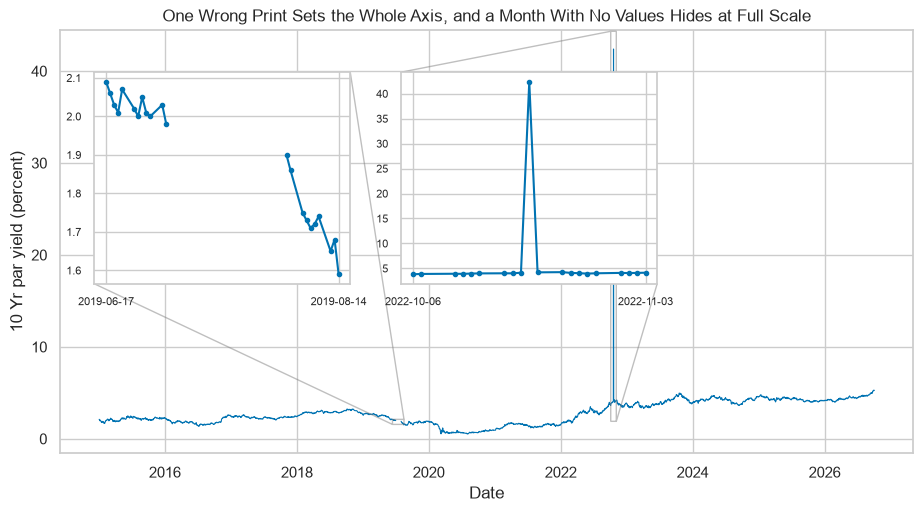

In [15]:
# the planted 10 Yr as received, with two close-ups drawn inside the chart
ten_year = planted["10 Yr"]
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(ten_year.index, ten_year, linewidth=0.8)
for corner, start, end in [([0.04, 0.4, 0.3, 0.5], "2019-06-17", "2019-08-14"), ([0.4, 0.4, 0.3, 0.5], "2022-10-06", "2022-11-03")]:
    inset = ax.inset_axes(corner)
    inset.plot(ten_year.loc[start:end], marker="o", markersize=3)
    inset.set_xticks([pd.Timestamp(start), pd.Timestamp(end)], labels=[start, end])
    inset.tick_params(labelsize=8)
    ax.indicate_inset_zoom(inset, edgecolor="gray")
ax.set(xlabel="Date", ylabel="10 Yr par yield (percent)",
       title="One Wrong Print Sets the Whole Axis, and a Month With No Values Hides at Full Scale")
plt.show()

At full scale the 10 Yr is a flat line near the bottom: one print of 42.40 sets the whole axis.

The October 2022 close-up shows it, one point far above its neighbours.

The July 2019 close-up shows the hole, easy to miss at full scale.

## Blanks Over Time

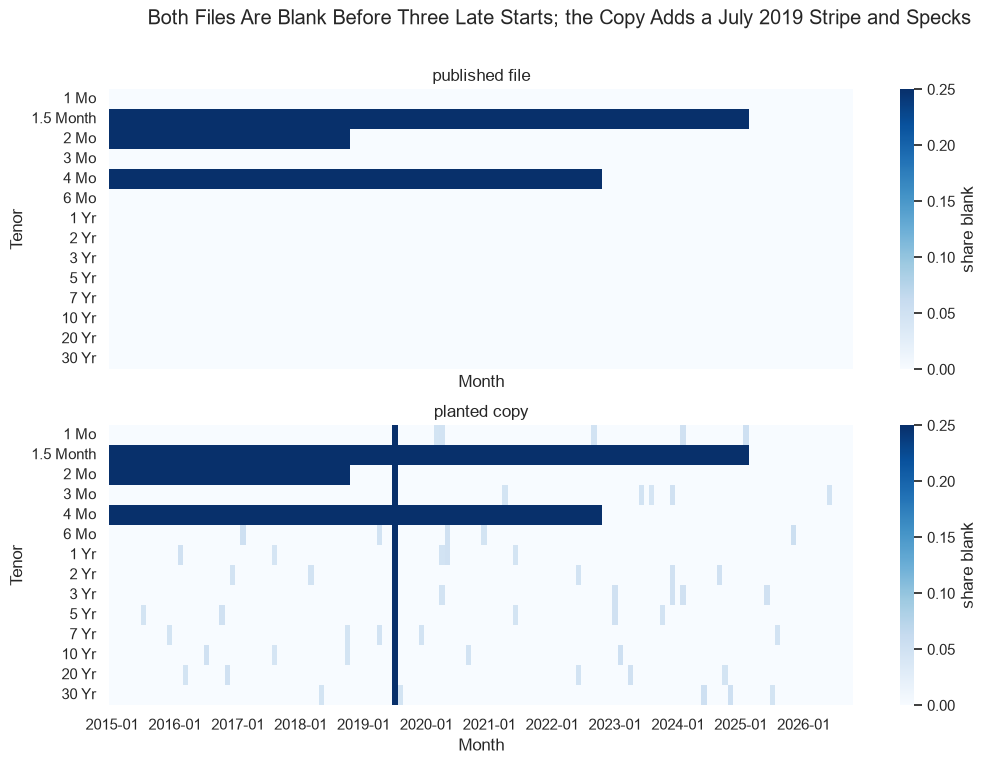

In [16]:
# the share of each month's cells that are blank, tenor by tenor: the published file above the planted copy
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, (name, frame) in zip(axes, [("published file", treasury), ("planted copy", planted)]):
    monthly = frame.isna().groupby(frame.index.to_period("M")).mean().T
    sns.heatmap(monthly, cmap="Blues", vmin=0, vmax=0.25, xticklabels=12, cbar_kws={"label": "share blank"}, ax=ax)
    ax.set(title=name, xlabel="Month", ylabel="Tenor")
fig.suptitle("Both Files Are Blank Before Three Late Starts; the Copy Adds a July 2019 Stripe and Specks")
plt.show()

Solid blocks at the top left: the three tenors before they started, in both files.

A stripe down every started tenor in July 2019: the outage.

Pale specks scattered across the copy: single blank days.

## Where the Weekdays Went

A bar of bars opens one slice of a stacked bar out to full height beside it, so a small slice can be read.

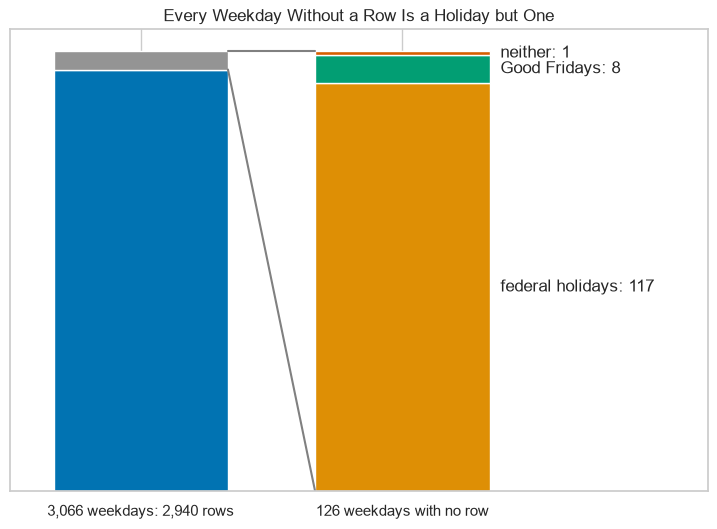

In [17]:
# the weekdays as one bar, and its absent days opened out to the same height and split by kind
fig, ax = plt.subplots(figsize=(9, 6))
ax.bar(0, len(treasury), color="C0")
ax.bar(0, len(absent), bottom=len(treasury), color="C7")
counts = pd.Series({"federal holidays": is_federal.sum(), "Good Fridays": is_good_friday.sum(), "neither": len(other)})
heights = counts * len(weekdays) / len(absent)
ax.bar(1.2, heights, bottom=heights.cumsum() - heights, color=["C1", "C2", "C3"])
for name, count, middle in zip(counts.index, counts, heights.cumsum() - heights / 2):
    ax.text(1.65, middle, name + ": " + str(count), va="center")
ax.plot([0.4, 0.8], [len(treasury), 0], color="gray")
ax.plot([0.4, 0.8], [len(weekdays), len(weekdays)], color="gray")
ax.set(xticks=[0, 1.2], xticklabels=["3,066 weekdays: 2,940 rows", "126 weekdays with no row"], yticks=[], xlim=(-0.6, 2.6),
       title="Every Weekday Without a Row Is a Holiday but One")
plt.show()

The weekdays split into 2,940 rows and 126 absent days, and nearly all of those are federal holidays.

**Two kinds of trouble need two hunts: numbers that are wrong, and cells that are blank. Wrong numbers come first, because a correction can leave a blank.**

# Finding Wrong Values

**Predict 1**

Q. A rule flags every daily move of more than 50 bp. On the published file, with nothing planted, how many cells does it flag? Write down a number.

## A Plain Rule: Every Move Over 50 bp

In [18]:
# each day's change in bp (Course 3's change: a level less the row before, times 100)
changes = treasury.diff() * 100

# the cells whose move is larger than 50 bp either way, with their change
big_moves = changes.abs() > 50
print(big_moves.sum().sum(), "cells flagged")
changes.where(big_moves).stack().dropna().round(1)

6 cells flagged


date            
2023-03-13  1 Yr    -60.0
            2 Yr    -57.0
2023-04-20  1 Mo    -55.0
2023-04-25  1 Mo     57.0
2023-05-04  1 Mo    106.0
2023-05-30  1 Mo    -71.0
dtype: float64

6 cells on 5 dates, every one in 2023: the 1 Yr and the 2 Yr on 2023-03-13, and four moves of the 1 Mo in April and May.

On Friday 2023-03-10 California's regulator closed Silicon Valley Bank and named the FDIC receiver ([FDIC, 2023-03-10](https://www.fdic.gov/news/press-releases/2023/pr23016.html)); on the Monday the 2 Yr in this file is 57 bp lower.

Real markets move that much, so a rule on size alone flags real days.

## A Jump That Comes Straight Back

A wrong print jumps away from its neighbours and comes straight back: a large move into the date, then a large move the other way.
Two moves have opposite signs when their product is negative.

In [19]:
# the flag sits on the row that comes back: its move and the move before both exceed bp, with opposite signs
def jump_and_back(frame, bp=50):
    change = frame.diff() * 100
    return (change.abs() > bp) & (change.shift(1).abs() > bp) & (change * change.shift(1) < 0)

print("published file:", jump_and_back(treasury).sum().sum(), "flags")
print("planted copy:", jump_and_back(planted).sum().sum(), "flags")

published file: 0 flags
planted copy: 3 flags


In [20]:
# the suspect is the row before each flag
flags = jump_and_back(planted)
suspects = []
for column in planted.columns:
    for date in planted.index[flags[column]]:
        suspect = planted.index[planted.index.get_loc(date) - 1]
        suspects.append((column, suspect))
        print(column, suspect.date(), "reads", round(planted.loc[suspect, column], 2))

2 Yr 2017-03-15 reads 133.0
5 Yr 2016-10-31 reads 2.58
10 Yr 2022-10-20 reads 42.4


No flag on the published file, three on the copy: the three planted dates.

The flag for a date uses that date and the two rows before it, never a later one.

### The Three Suspects

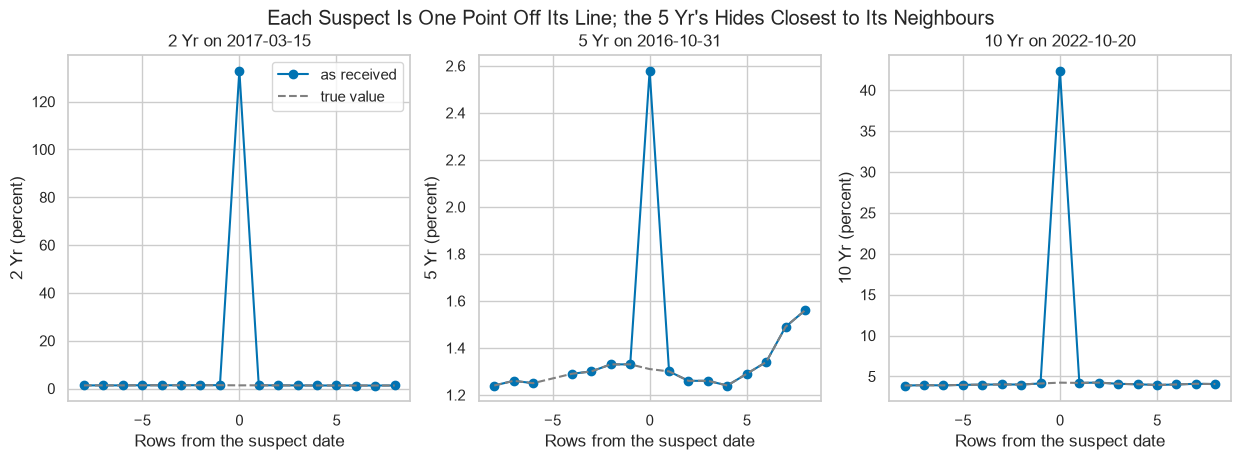

In [21]:
# each suspect with eight rows either side: as received, and the true value dashed
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (column, date) in zip(axes, suspects):
    at = planted.index.get_loc(date)
    ax.plot(range(-8, 9), planted[column].iloc[at - 8:at + 9], marker="o", label="as received")
    ax.plot(range(-8, 9), treasury[column].iloc[at - 8:at + 9], color="gray", linestyle="--", label="true value")
    ax.set(title=column + " on " + str(date.date()), xlabel="Rows from the suspect date", ylabel=column + " (percent)")
axes[0].legend()
fig.suptitle("Each Suspect Is One Point Off Its Line; the 5 Yr's Hides Closest to Its Neighbours")
plt.show()

The 2 Yr reads 133.00 where the truth is 1.33: a yield printed in bp.

The 5 Yr reads 2.58, the 30 Yr's yield that day, where the truth is 1.31.

The 10 Yr reads 42.40 where the truth is 4.24.

## Checking Against a Second Source

In [22]:
# the cells both sources hold, and their gap in bp
both = planted.loc[backup.index, backup.columns]
gap_bp = (both - backup).abs() * 100
print(both.notna().sum().sum(), "cells in both,", (gap_bp > 0.5).sum().sum(), "apart by more than half a bp")
gap_bp.where(gap_bp > 0.5).stack().dropna()

2874 cells in both, 1 apart by more than half a bp


date             
2022-10-20  10 Yr    3816.0
dtype: float64

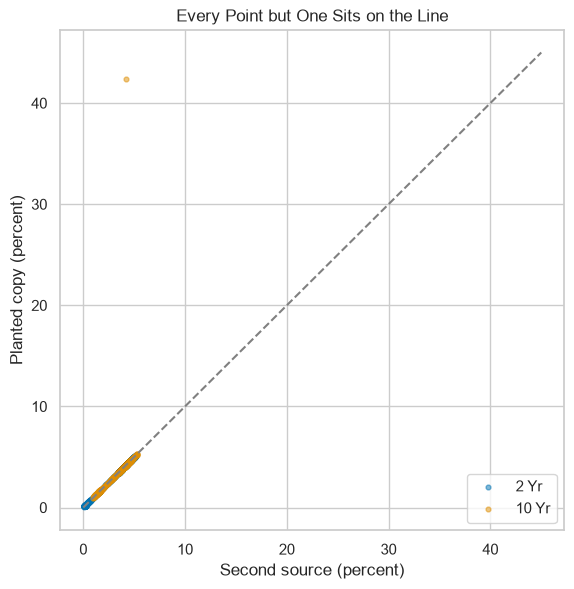

In [23]:
# the copy's value against the second source's, every date both hold; agreement sits on the dashed line
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for column in backup.columns:
    ax.scatter(backup[column], both[column], s=12, alpha=0.5, label=column)
ax.plot([0, 45], [0, 45], color="gray", linestyle="--")
ax.set(xlabel="Second source (percent)", ylabel="Planted copy (percent)",
       title="Every Point but One Sits on the Line")
ax.legend()
plt.show()

One disagreement in 2,874 cells: the 10 Yr on 2022-10-20, 3,816 bp apart.

The 2 Yr's print of 2017 is older than the sheet, and the 5 Yr is not in it: only the shape rule found those two.

**Three wrong values found two ways. Next we correct them so that each change leaves a record.**

# Correcting Wrong Values

## One Cell by Hand

In [24]:
# a copy, and one cell set from the second source with .loc[date, column]
by_hand = planted.copy()
by_hand.loc[wrong_10y, "10 Yr"] = backup.loc[wrong_10y, "10 Yr"]
print(round(planted.loc[wrong_10y, "10 Yr"], 2), "became", by_hand.loc[wrong_10y, "10 Yr"])

42.4 became 4.24


It works, and nothing records what changed, from what, or why.

## A Corrections Table

In [25]:
# one row per cell to correct: the date, the column, the checked value, and where it came from
corrections = pd.DataFrame({
    "date": [wrong_5y, wrong_2y, wrong_10y],
    "column": ["5 Yr", "2 Yr", "10 Yr"],
    # no checked 5 Yr value is to hand, so its correction is a blank: the print is known to be wrong
    "value": [np.nan, planted.loc[wrong_2y, "2 Yr"] / 100, backup.loc[wrong_10y, "10 Yr"]],
    "source": ["30 Yr yield in the 5 Yr column", "printed in bp", "end-of-day sheet"],
})
corrections

,date,column,value,source
0,2016-10-31,5 Yr,NaN,30 Yr yield in the 5 Yr column
1,2017-03-15,2 Yr,1.33,printed in bp
2,2022-10-20,10 Yr,4.24,end-of-day sheet


The 5 Yr's `NaN` is on purpose: a known wrong value with nothing checked to replace it.

## Applying the Table With `update`

`frame.update(other)` writes each value of `other` into `frame`, matched on row and column labels.
`pivot(index=, columns=, values=)` (Course 4) turns the table into that shape: a row per date, a column per tenor.

**Predict 2**

Q. The table holds three corrections. How many of them will `update` apply? Write down a number.

In [26]:
# the corrections as a frame of dates by tenors, written into a copy with update
updated = planted.copy()
updated.update(corrections.pivot(index="date", columns="column", values="value"))
for date, column in zip(corrections["date"], corrections["column"]):
    print(column, date.date(), round(planted.loc[date, column], 2), "became", round(updated.loc[date, column], 2))

5 Yr 2016-10-31 2.58 became 2.58
2 Yr 2017-03-15 133.0 became 1.33
10 Yr 2022-10-20 42.4 became 4.24


### Interpretation of `update`

Two of the three changed; the 5 Yr still reads 2.58.

`update` skips every `NaN` it is given, with no error and no warning, so it can never blank a cell.

## A Plain Loop and a Change Log

`for _, row in corrections.iterrows()` visits the table one row at a time (Course 4).

In [27]:
# write each correction into a copy, and log the old value beside the new one
corrected = planted.copy()
log = []
for _, row in corrections.iterrows():
    old = corrected.loc[row["date"], row["column"]]
    corrected.loc[row["date"], row["column"]] = row["value"]
    log.append({"date": row["date"], "column": row["column"], "old": old, "new": row["value"], "source": row["source"]})
pd.DataFrame(log)

,date,column,old,new,source
0,2016-10-31,5 Yr,2.58,NaN,30 Yr yield in the 5 Yr column
1,2017-03-15,2 Yr,133.00,1.33,printed in bp
2,2022-10-20,10 Yr,42.40,4.24,end-of-day sheet


All three applied, the blank included, and each is on record.

## Filling From the Second Source

`a.combine_first(b)` keeps `a`'s value wherever it has one and takes `b`'s where `a` is blank.

In [28]:
# the second source fills the blanks it can; combine_first sorts the columns, so we put back the file's order
repaired = corrected.combine_first(backup)[corrected.columns]
from_backup = corrected[backup.columns].isna() & repaired[backup.columns].notna()
print(from_backup.sum().sum(), "cells filled from the second source")

4 cells filled from the second source


In [29]:
# each filled cell joins the log
for column in backup.columns:
    for date in from_backup.index[from_backup[column]]:
        log.append({"date": date, "column": column, "old": np.nan, "new": repaired.loc[date, column], "source": "second source"})
change_log = pd.DataFrame(log)
change_log

,date,column,old,new,source
0,2016-10-31,5 Yr,2.58,NaN,30 Yr yield in the 5 Yr column
1,2017-03-15,2 Yr,133.00,1.33,printed in bp
2,2022-10-20,10 Yr,42.40,4.24,end-of-day sheet
3,2022-06-17,2 Yr,NaN,3.17,second source
4,2023-12-05,2 Yr,NaN,4.57,second source
5,2024-09-18,2 Yr,NaN,3.61,second source
6,2023-02-06,10 Yr,NaN,3.63,second source


Four planted blanks had a value in the sheet: three in the 2 Yr and one in the 10 Yr.

The log holds seven changes, each with its old value, its new value and its source.

**Every value is now right or blank on purpose, and every change is in the log. What is left is blanks.**

# Finding Gaps Inside a Series

## Runs of Blank Cells

Course 3's run method, on blanks: a new run starts wherever a cell turns blank or turns back, `cumsum` numbers the runs, and `groupby` collects each one.

In [30]:
# every run of blank cells in every column: its tenor, first date, and length in rows
runs = []
for column in repaired.columns:
    blank = repaired[column].isna()
    run_id = (blank != blank.shift()).cumsum()
    for _, run in blank[blank].groupby(run_id[blank]):
        runs.append({"tenor": column, "start": run.index[0], "rows": len(run)})
runs = pd.DataFrame(runs)
runs["rows"].value_counts()

rows
1       52
20      12
2532     1
949      1
1951     1
Name: count, dtype: int64

52 runs of one day, 12 runs of 20 days, and three long runs at the top of the late tenors.

The outage is a run in 11 full tenors and the `2 Mo`; the `4 Mo` and `1.5 Month` had not started.

### Runs Over Time

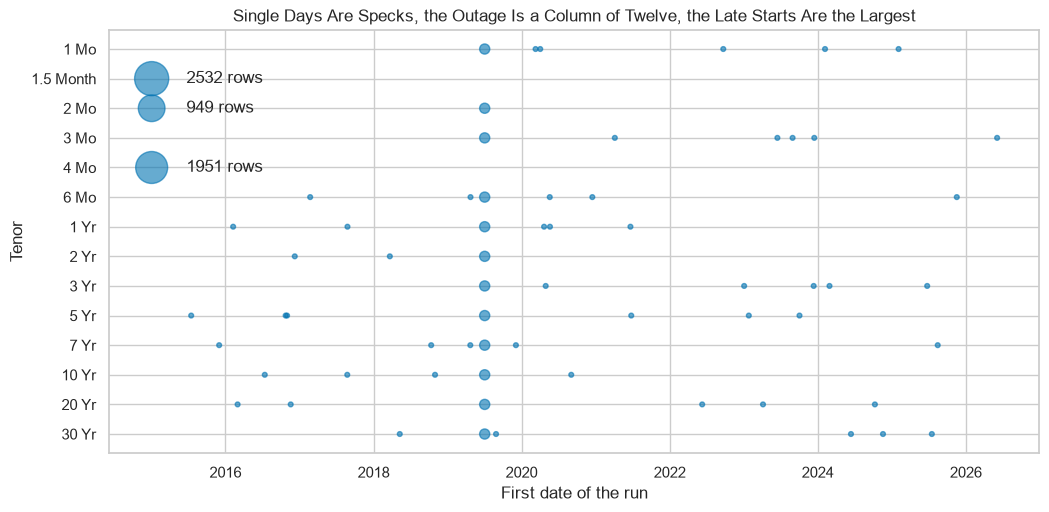

In [31]:
# every run of blanks as a bubble: tenor down, first date across, area growing with the run's length in rows
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.scatter(runs["start"], runs["tenor"], s=12 * np.sqrt(runs["rows"]), alpha=0.6)
for _, run in runs[runs["rows"] > 20].iterrows():
    ax.annotate(str(run["rows"]) + " rows", (run["start"], run["tenor"]), xytext=(25, 0), textcoords="offset points", va="center")
ax.invert_yaxis()
ax.set(xlabel="First date of the run", ylabel="Tenor",
       title="Single Days Are Specks, the Outage Is a Column of Twelve, the Late Starts Are the Largest")
plt.show()

The outage lines up in July 2019 down every tenor that had started.

## The Cells to Fill

In [32]:
# the cells to fill: blank in the repaired copy, with a true value held back
to_fill = repaired.isna() & treasury.notna()

# split them: the outage dates, and every other date (the single days)
outage_cells = to_fill.copy()
outage_cells.loc[~outage_cells.index.isin(outage_dates)] = False
single_cells = to_fill & ~outage_cells
print(single_cells.sum().sum(), "single-day cells,", outage_cells.sum().sum(), "outage cells")

52 single-day cells, 240 outage cells


52 single-day cells and 240 outage cells, each with its true value held back.

**One blank day and a 20-day outage are different problems, so every fill is scored on both.**

# Filling the Gaps

![Four rows, one per fill, over five dates from Thursday to Wednesday: a known value of 2.00 on Thursday, blanks on Friday, Monday and Tuesday, and a known 2.30 on Wednesday. Forward fill reads the value before only. Backfill reads the value after only. Linear interpolation reads both and counts rows. Time interpolation reads both and counts calendar days, so Friday to Monday is one row but three days. Only forward fill reads no later date](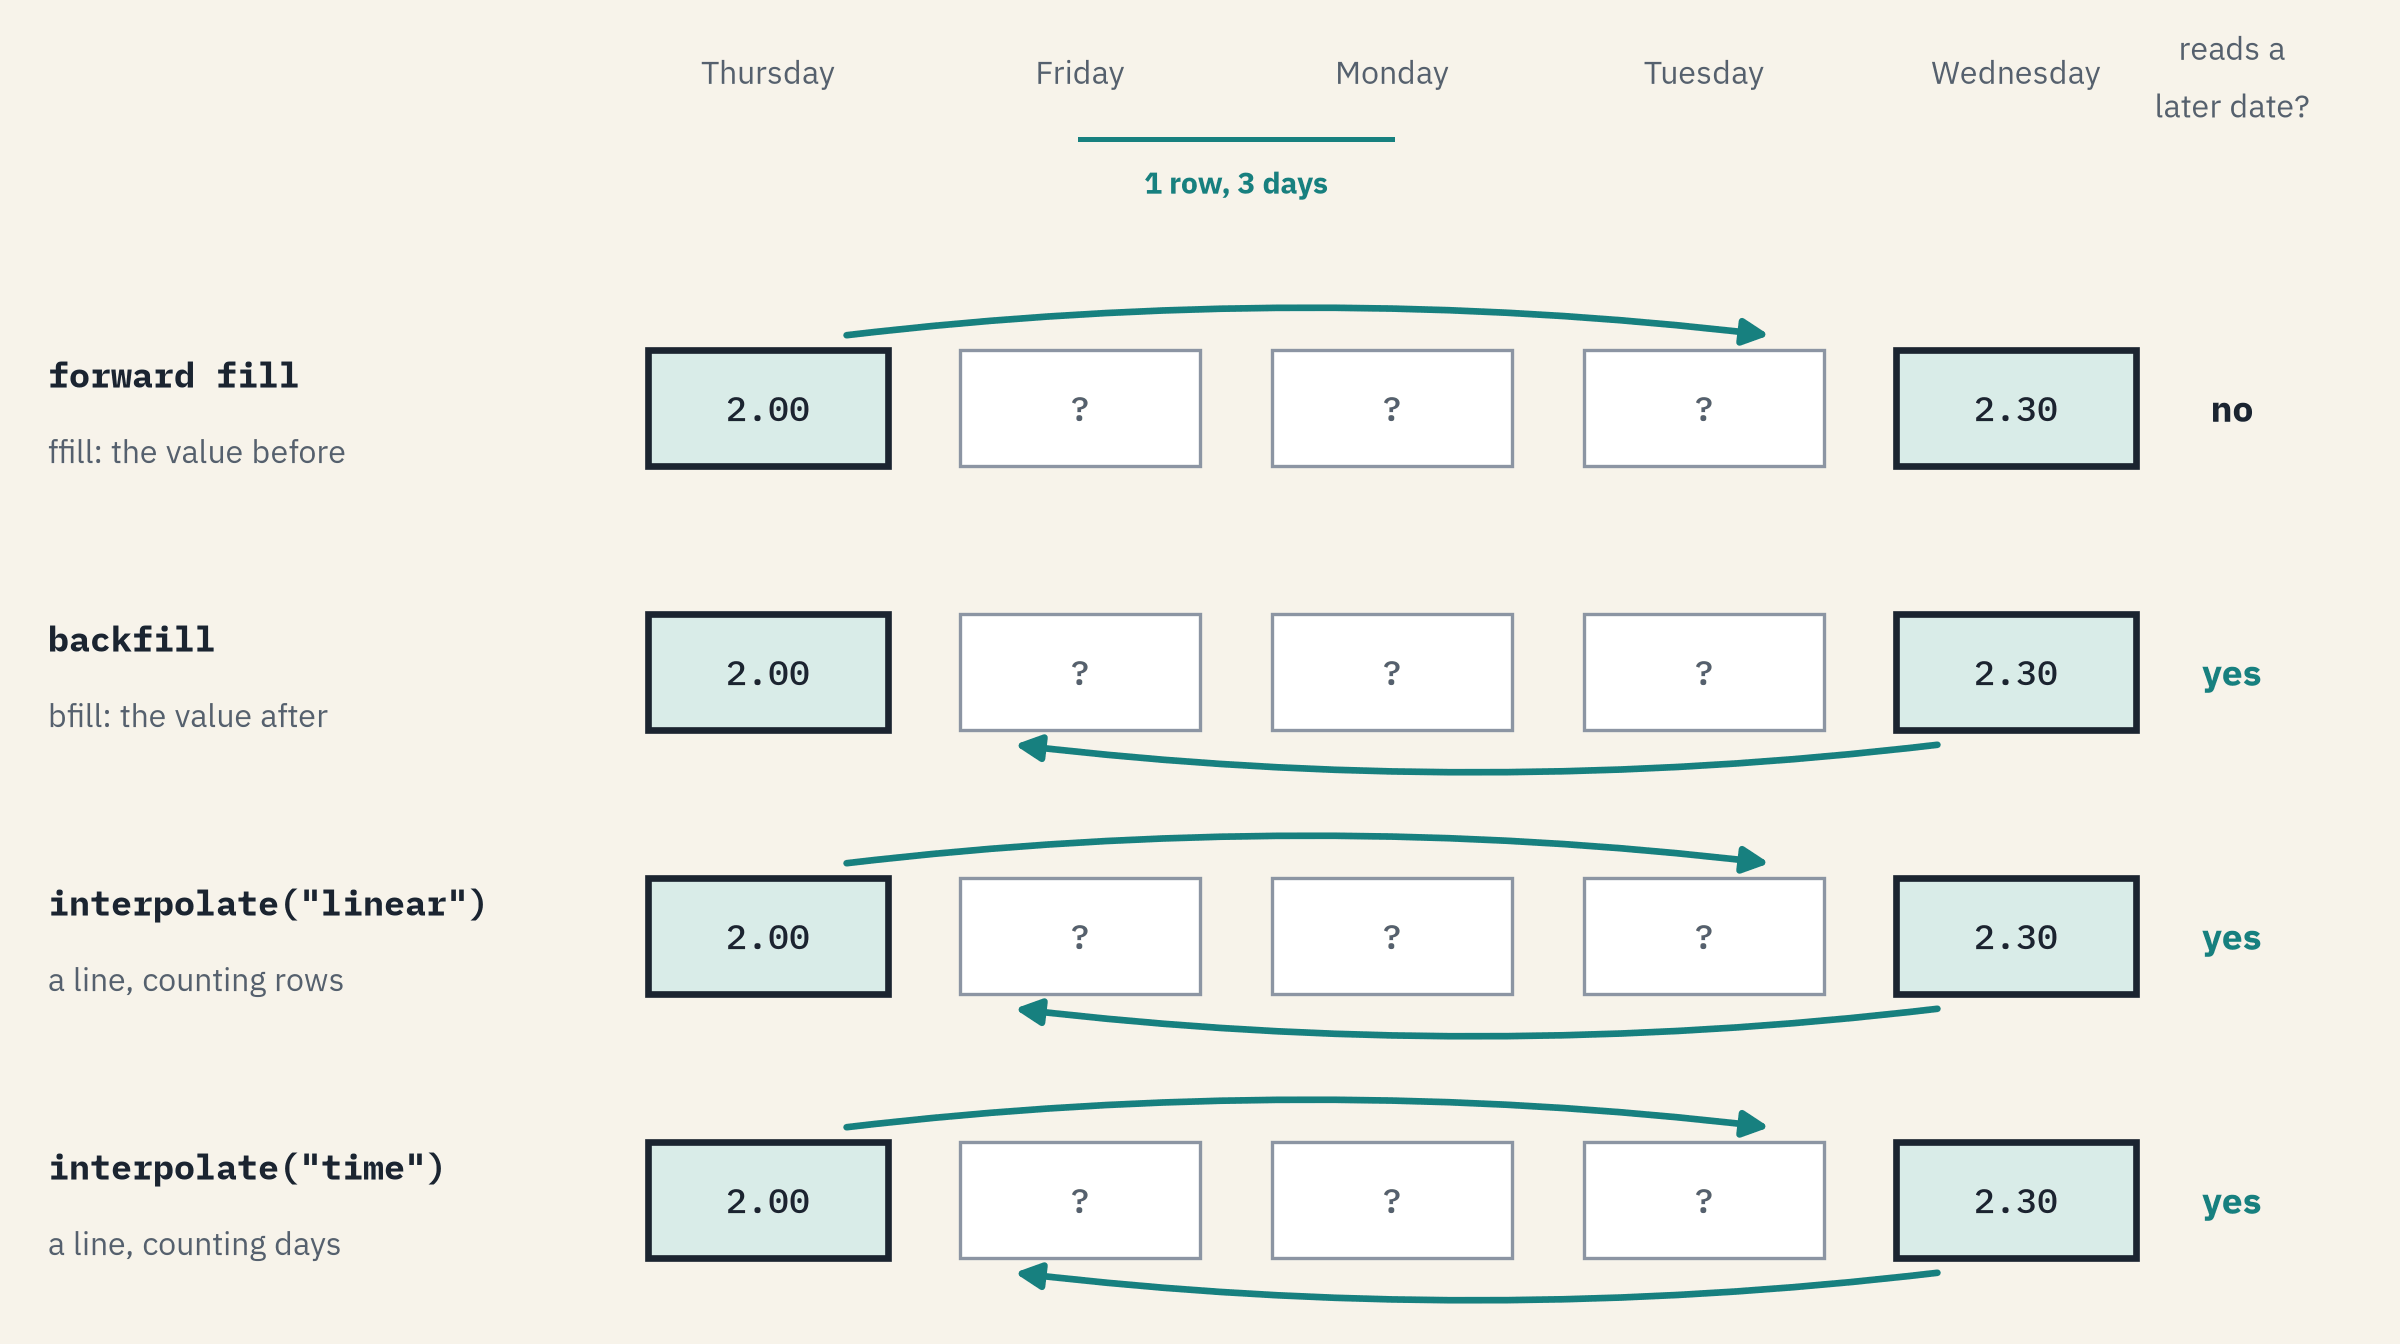)

A **forward fill** carries the last value on (Course 3's `ffill`), and a **backfill** (`bfill`) takes the next one.
Linear interpolation draws a straight line between the values either side, Course 2's interpolation along time instead of maturity.
`method="linear"` spaces the dates by rows, `method="time"` by calendar days.

## Four Fills

In [33]:
# a demonstration: four ways to fill the same blanks, the backfill among them to show what it does
fills = {"ffill": repaired.ffill(), "bfill": repaired.bfill(),
         "linear": repaired.interpolate(method="linear"), "time": repaired.interpolate(method="time")}
for name, filled in fills.items():
    print(name, filled.isna().sum().sum(), "cells still blank")

ffill 5432 cells still blank
bfill 0 cells still blank
linear 5432 cells still blank
time 5432 cells still blank


Three fills leave 5,432 cells blank: the late tenors before they started.

The backfill leaves none: it filled every not-started cell with the series' first value.

**Predict 3**

Q. Across the outage the 10 Yr reads 1.98 on the row before and 1.90 on the row after. Sketch the forward fill and the time interpolation across the 20 blank dates, then sketch where you think the true values ran. Which fill lands closer?

## The Fills Against the True Values

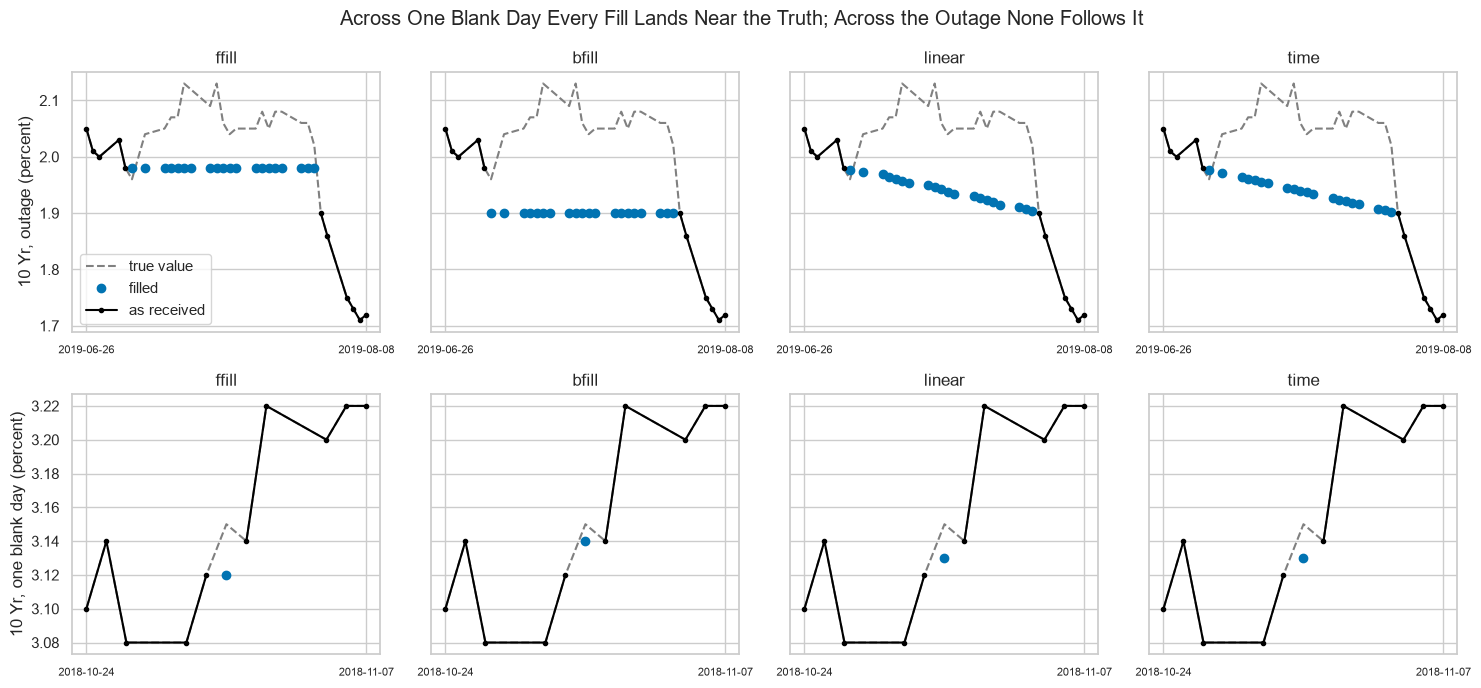

In [34]:
# each fill of the 10 Yr against the true values: the outage on the top row, one blank day on the bottom
fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharey="row")
for row, (start, end) in enumerate([("2019-06-26", "2019-08-08"), ("2018-10-24", "2018-11-07")]):
    for ax, (name, filled) in zip(axes[row], fills.items()):
        ax.plot(treasury.loc[start:end, "10 Yr"], color="gray", linestyle="--", label="true value")
        ax.plot(filled.loc[start:end, "10 Yr"].where(to_fill.loc[start:end, "10 Yr"]), marker="o", linestyle="none", label="filled")
        ax.plot(repaired.loc[start:end, "10 Yr"], marker="o", markersize=3, color="black", label="as received")
        # a date label at each end of a panel only, so they do not overlap
        ax.set(title=name, xticks=[pd.Timestamp(start), pd.Timestamp(end)])
        ax.tick_params(axis="x", labelsize=8)
axes[0, 0].set_ylabel("10 Yr, outage (percent)")
axes[1, 0].set_ylabel("10 Yr, one blank day (percent)")
axes[0, 0].legend()
fig.suptitle("Across One Blank Day Every Fill Lands Near the Truth; Across the Outage None Follows It")
plt.tight_layout()
plt.show()

On the single day every fill lands near the truth.

On the outage, the true values climb away from both ends and back.

## Scoring Each Fill

Each fill is scored by its mean absolute error in bp against the held-back values (Course 4's MAE), on the two kinds of cell apart.

In [35]:
# each fill's MAE in bp on the single-day cells and the outage cells, and its largest outage miss
scores = []
for name, filled in fills.items():
    miss_bp = (filled - treasury).abs() * 100
    scores.append({"fill": name, "single days": miss_bp[single_cells].stack().mean(),
                   "outage": miss_bp[outage_cells].stack().mean(), "outage, largest": miss_bp[outage_cells].max().max()})
scores = pd.DataFrame(scores).set_index("fill").round(2)
scores

,single days,outage,"outage, largest"
fill,,,
ffill,2.67,6.97,20.00
bfill,3.25,10.97,23.00
linear,2.12,8.25,18.43
time,2.04,8.35,18.73


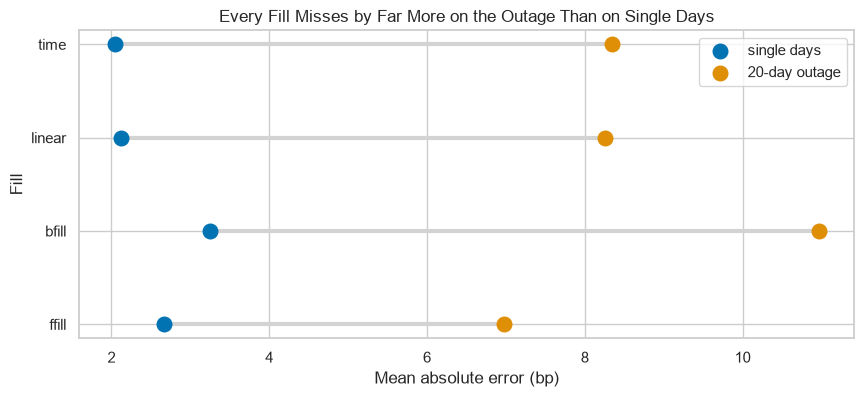

In [36]:
# each fill's MAE on single days and on the outage, joined by a line
fig, ax = plt.subplots(figsize=(10, 4))
ax.hlines(scores.index, scores["single days"], scores["outage"], color="lightgray", linewidth=3)
ax.scatter(scores["single days"], scores.index, s=110, label="single days", zorder=3)
ax.scatter(scores["outage"], scores.index, s=110, label="20-day outage", zorder=3)
ax.set(xlabel="Mean absolute error (bp)", ylabel="Fill", title="Every Fill Misses by Far More on the Outage Than on Single Days")
ax.legend()
plt.show()

On single days the interpolations are closest: time 2.04 bp, linear 2.12, forward fill 2.67.

On the outage the forward fill is closest on average, 6.97 bp against 8.35 for time interpolation.

In [37]:
# the outage MAE tenor by tenor, forward fill against time interpolation, and the true 10 Yr's range across the outage
by_tenor = pd.DataFrame({name: ((fills[name] - treasury).abs() * 100)[outage_cells].mean() for name in ["ffill", "time"]})
by_tenor = by_tenor.dropna().round(2)
print("forward fill closer in", (by_tenor["ffill"] < by_tenor["time"]).sum(), "of", len(by_tenor), "tenors")
print("true 10 Yr across the outage:", treasury.loc[outage_dates, "10 Yr"].min(), "to", treasury.loc[outage_dates, "10 Yr"].max())
by_tenor.T

forward fill closer in 9 of 12 tenors
true 10 Yr across the outage: 1.96 to 2.13


,1 Mo,2 Mo,3 Mo,6 Mo,1 Yr,2 Yr,3 Yr,5 Yr,7 Yr,10 Yr,20 Yr,30 Yr
ffill,7.25,3.05,7.70,2.75,5.70,7.10,9.60,8.50,8.85,8.65,7.40,7.10
time,2.90,2.82,3.09,3.19,7.17,9.19,11.69,12.13,13.00,12.80,11.55,10.73


The true 10 Yr ran from 1.96 to 2.13, above both ends on 19 of the 20 dates, so the line from 1.98 to 1.90 leaned the wrong way.

The forward fill is closer in 9 of 12 tenors, the 10 Yr's 8.65 bp against 12.80.

Another outage, with the curve moving the other way, could order them differently.

## Where a Series Starts

`limit_direction="both"` lets interpolation fill outward in both directions from each value.
`limit_area="inside"` fills only blanks with a value on each side.

In [38]:
# a demonstration: three fills of the 2 Mo, and how many values each puts before its first true date
start_2mo = treasury["2 Mo"].first_valid_index()
starts = {"bfill": repaired["2 Mo"].bfill(),
          'limit_direction="both"': repaired["2 Mo"].interpolate(method="time", limit_direction="both"),
          'limit_area="inside"': repaired["2 Mo"].interpolate(method="time", limit_area="inside")}
for name, filled in starts.items():
    print(name, filled.loc[:start_2mo].iloc[:-1].notna().sum(), "values before", start_2mo.date())

bfill 949 values before 2018-10-16
limit_direction="both" 949 values before 2018-10-16
limit_area="inside" 0 values before 2018-10-16


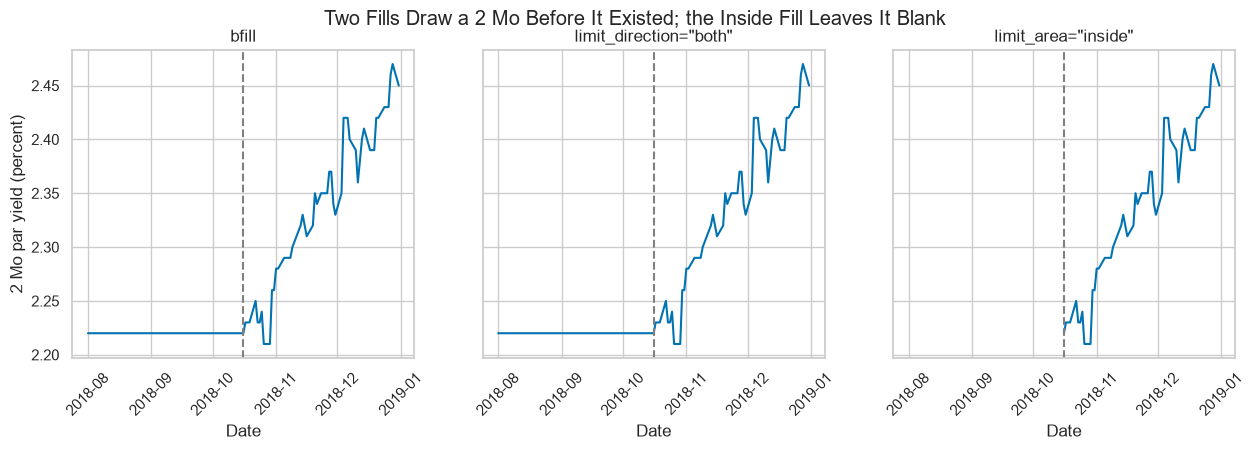

In [39]:
# the three fills of the 2 Mo around its first date, the first date dashed
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, (name, filled) in zip(axes, starts.items()):
    ax.plot(filled.loc["2018-08-01":"2018-12-31"], linewidth=1.5)
    ax.axvline(start_2mo, color="gray", linestyle="--")
    ax.set(title=name, xlabel="Date")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("2 Mo par yield (percent)")
fig.suptitle("Two Fills Draw a 2 Mo Before It Existed; the Inside Fill Leaves It Blank")
plt.show()

The backfill and the fill in both directions put 949 values before the 2 Mo started, flat at its first value.

`limit_area="inside"` puts none there.

**The lowest error does not choose the fill. What the series is for does.**

# Which Fill When

Forward fill for a quote you could have traded on that date: the last value published.

Interpolation for a point on a curve, or a description of history, where both ends are known.

Never a later value in anything scored date by date.

## The Cut Test on Two Fills

Course 3's cut test asks whether a value for a date changes when later rows arrive: run the same steps on the whole file and on the file cut at a date, and compare the rows up to and including the cut.
We cut on the outage's tenth date.

**Predict 4**

Q. Up to the cut the outage holds 120 blank cells, 10 dates in 12 tenors. For how many of them does the filled value change between the whole file and the cut file: with the forward fill, and with the time interpolation? Write down two numbers.

In [40]:
# a demonstration of the leak: each fill run on the file cut on the outage's tenth date, against the whole file's fill
cut = outage_dates[9]
cut_fills = {"ffill": repaired.loc[:cut].ffill(), "time": repaired.loc[:cut].interpolate(method="time")}
for name, cut_fill in cut_fills.items():
    changed = (fills[name].loc[:cut] != cut_fill) & outage_cells.loc[:cut]
    print(name, changed.sum().sum(), "of", outage_cells.loc[:cut].sum().sum(), "outage cells up to", cut.date(), "changed")

ffill 0 of 120 outage cells up to 2019-07-17 changed
time 120 of 120 outage cells up to 2019-07-17 changed


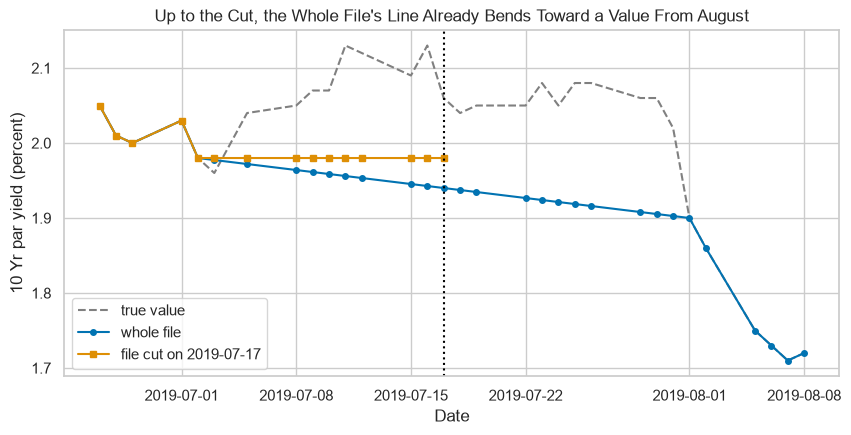

In [41]:
# the 10 Yr across the outage: time interpolation on the whole file and on the file cut at the dotted line
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(treasury.loc["2019-06-26":"2019-08-08", "10 Yr"], color="gray", linestyle="--", label="true value")
ax.plot(fills["time"].loc["2019-06-26":"2019-08-08", "10 Yr"], marker="o", markersize=4, label="whole file")
ax.plot(cut_fills["time"].loc["2019-06-26":, "10 Yr"], marker="s", markersize=4, label="file cut on " + str(cut.date()))
ax.axvline(cut, color="black", linestyle=":")
ax.set(xlabel="Date", ylabel="10 Yr par yield (percent)",
       title="Up to the Cut, the Whole File's Line Already Bends Toward a Value From August")
ax.legend()
plt.show()

### Interpretation of the Cut Test

The forward fill reads only earlier dates, so not one of its values moves.

Every interpolated value up to the cut moves: on the whole file each one leans toward 1.90 on 2019-08-01, a value the cut file does not have.

A series scored date by date with such a fill holds, on each date, a number from a later one.

**A series that will be scored is forward filled, and only so far.**

# A Long Outage

## Capping a Fill With `limit`

`limit=n` fills at most `n` blanks in a row and leaves the rest of the run blank.

In [42]:
# the outage cells each limit fills, and the MAE in bp on the cells it fills, forward fill against time interpolation
sweep = []
for limit in [1, 2, 3, 5, 10, 15, 20]:
    ffill_miss = ((repaired.ffill(limit=limit) - treasury).abs() * 100)[outage_cells]
    time_miss = ((repaired.interpolate(method="time", limit=limit, limit_area="inside") - treasury).abs() * 100)[outage_cells]
    sweep.append({"limit": limit, "cells filled": ffill_miss.count().sum(),
                  "ffill MAE (bp)": ffill_miss.stack().mean(), "time MAE (bp)": time_miss.stack().mean()})
pd.DataFrame(sweep).set_index("limit").round(2)

,cells filled,ffill MAE (bp),time MAE (bp)
limit,,,
1,12,1.83,1.82
2,24,4.12,4.45
3,36,5.08,5.74
5,60,5.72,6.65
10,120,6.84,7.77
15,180,6.66,7.70
20,240,6.97,8.35


A limit of 1 fills 12 outage cells and misses by 1.83 bp; a limit of 20 fills all 240 and misses by 6.97.

## Your Turn: Slide the Limit

In [43]:
# your turn: slide the limit and watch how far each fill reaches into the 10 Yr's outage
def draw_limit(limit=5):
    plt.plot(treasury.loc["2019-06-26":"2019-08-08", "10 Yr"], color="gray", linestyle="--", label="true value")
    plt.plot(repaired["10 Yr"].ffill(limit=limit).loc["2019-06-26":"2019-08-08"], marker="o", markersize=4, label="forward fill")
    interpolated = repaired["10 Yr"].interpolate(method="time", limit=limit, limit_area="inside")
    plt.plot(interpolated.loc["2019-06-26":"2019-08-08"], marker="s", markersize=4, label="time interpolation")
    plt.xlabel("Date")
    plt.ylabel("10 Yr par yield (percent)")
    plt.title(f"With limit={limit}, Each Fill Stops {limit} Rows Into the Outage")
    plt.legend()
    plt.show()

interact(draw_limit, limit=(1, 20));

interactive(children=(IntSlider(value=5, description='limit', max=20, min=1), Output()), _dom_classes=('widget…

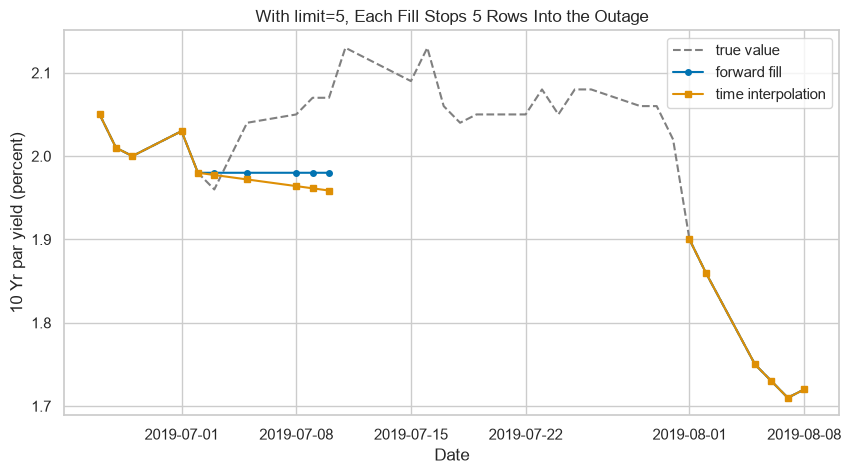

In [44]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_limit(limit=5)

Every row past `limit` stays blank.

## Error by Rows Into the Outage

In [45]:
# the mean miss in bp over the 12 tenors at each row into the outage, for each fill
by_row = pd.DataFrame({name: ((fills[name] - treasury).abs() * 100).loc[outage_dates].mean(axis=1).to_numpy()
                       for name in ["ffill", "time"]}, index=range(1, 21))
print("row 1:", by_row.loc[1].round(2).to_dict())
print("rows where time interpolation misses by more:", (by_row["time"] > by_row["ffill"]).sum(), "of 20")

row 1: {'ffill': 1.83, 'time': 1.82}
rows where time interpolation misses by more: 19 of 20


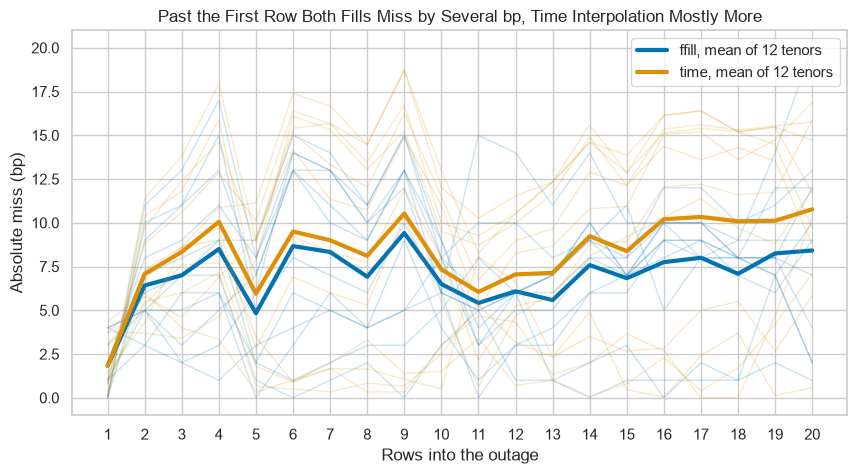

In [46]:
# the miss at each row into the outage: each tenor faint, the mean of the 12 bold
fig, ax = plt.subplots()
for name, colour in [("ffill", "C0"), ("time", "C1")]:
    miss = ((fills[name] - treasury).abs() * 100).loc[outage_dates].dropna(axis=1)
    ax.plot(range(1, 21), miss.to_numpy(), color=colour, alpha=0.2, linewidth=1)
    ax.plot(by_row.index, by_row[name], color=colour, linewidth=3, label=name + ", mean of 12 tenors")
ax.set_xticks(range(1, 21))
ax.set(xlabel="Rows into the outage", ylabel="Absolute miss (bp)", title="Past the First Row Both Fills Miss by Several bp, Time Interpolation Mostly More")
ax.legend()
plt.show()

The first row misses by under 2 bp either way.

From row 2 on the forward fill misses by 4.83 to 9.42 bp, and the time interpolation misses by more on 19 of the 20 rows.

## Keeping the Gap Visible

In [47]:
# a forward fill that stops after 5 blanks: a quote at most five market dates old
limited = repaired.ffill(limit=5)
still_blank = limited["10 Yr"].isna()
print("10 Yr dates still blank:", still_blank.sum(), "from", limited.index[still_blank][0].date(), "to", limited.index[still_blank][-1].date())

10 Yr dates still blank: 15 from 2019-07-11 to 2019-07-31


In [48]:
# a scored series keeps only its dates with a value, and says how many it left out
kept = limited["10 Yr"].dropna()
print(len(kept), "of", len(limited), "dates kept;", len(limited) - len(kept), "left out")

2925 of 2940 dates kept; 15 left out


The last 15 outage dates stay blank, and the count of dates left out goes with every score.

**A capped fill admits what it does not know, and the score says how many dates it left out.**

# Insights and Conclusion

Four kinds of missing, four repairs: an absent row stays absent, a series starts at its first value, a blank is filled or left blank, a wrong value is corrected on record.

A rule on size flags real days; a jump that comes straight back, and a second source, find wrong prints.

`update` skips every `NaN`, so a correction that blanks a value needs a loop and a log.

Interpolation is closest on single blank days; over this 20-day outage the forward fill was closer in 9 of 12 tenors, and another outage could order them differently.

Any fill that reads a later date fails the cut test, so a scored series is forward filled, and capped.

**Day 2 builds changes and lags on the published file, which has no blank inside any tenor's span.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Tell an absent row, a blank cell, a series not started yet and a wrong value apart, and count each.
* Check dated rows against the market calendar.
* Find wrong values by their shape and by a second source, and correct them with a corrections table and a change log.
* Find runs of blank cells, fill them four ways, and score each fill against held-back values.
* Test a fill with the cut test, and cap it with `limit=`.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [49]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**The 5 Yr Across the Curve**

Q. The 5 Yr on 2016-10-31 is blank in `repaired`. Fill it across the curve instead of along time: Course 2's linear interpolation between that date's 3 Yr and 7 Yr. Store the value in percent in `ex1_five_year` and its miss against the true value, in bp, in `ex1_miss_bp`.

In [50]:
# the 3 Yr and 7 Yr on that date, and the straight line between them read at 5 years
row = repaired.loc[wrong_5y]
ex1_five_year = row["3 Yr"] + (row["7 Yr"] - row["3 Yr"]) * (5 - 3) / (7 - 3)
ex1_miss_bp = abs(ex1_five_year - treasury.loc[wrong_5y, "5 Yr"]) * 100
print("across the curve:", round(ex1_five_year, 4), "percent, a miss of", round(ex1_miss_bp, 2), "bp")
print("along time:", round(abs(fills["time"].loc[wrong_5y, "5 Yr"] - treasury.loc[wrong_5y, "5 Yr"]) * 100, 2), "bp")

across the curve: 1.31 percent, a miss of 0.0 bp
along time: 0.25 bp


Across the curve the 5 Yr lands on the true value; along time it misses by a quarter of a bp.

A blank on one tenor of a curve that is there on the others is a point on a curve: interpolate across maturity.

In [51]:
check("Exercise 1 the 5 Yr across the curve", ex1_five_year, 1.31)
check("Exercise 1 its miss in bp", ex1_miss_bp, 0.0)

Exercise 1 the 5 Yr across the curve: correct
Exercise 1 its miss in bp: correct


### Exercise 2

**A Function That Counts a Fill**

Q. Write `count_filled(before, after)` that returns how many cells are blank in `before` and hold a value in `after`, and store `count_filled(repaired, limited)` in `ex2_count`.

In [52]:
# blank before, a value after: the cells the fill wrote
def count_filled(before, after):
    """How many cells are blank in before and hold a value in after."""
    return (before.isna() & after.notna()).sum().sum()

ex2_count = count_filled(repaired, limited)
print(ex2_count)

112


52 single days and 60 outage cells, 5 rows into the outage in each of 12 tenors.

In [53]:
check("Exercise 2 the cells the capped fill filled", ex2_count, 112)

Exercise 2 the cells the capped fill filled: correct


### Exercise 3

**A Tighter Rule on the Published File**

Q. Run `jump_and_back` on `treasury` with `bp=25`. Store the number of flags in `ex3_flags`, look at each flagged cell, and say whether you think it is a wrong print.

In [54]:
# the rule at 25 bp on the published file, and the cells it flags
flags_25 = jump_and_back(treasury, bp=25)
ex3_flags = flags_25.sum().sum()
print(ex3_flags, "flags")
changes.where(flags_25).stack().dropna().round(1)

3 flags


date             
2017-09-06  1 Mo    -26.0
2020-03-10  30 Yr    29.0
2023-03-16  1 Yr     30.0
dtype: float64

Three flags, each on the move that comes back.

They sit in the published file, where nothing was planted: a shape rule finds suspects, and only a second source can say whether one is wrong.

In [55]:
check("Exercise 3 the flags at 25 bp", ex3_flags, 3)

Exercise 3 the flags at 25 bp: correct


### Exercise 4: AI check

**The Fill That Promised to Stop**

You asked an AI assistant for a function that fills short runs of blanks and leaves long ones blank.
This came back.
It runs, and the 10 Yr comes back with no blank date.
Test it against its own docstring, then find the one bug.

In [56]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def fill_short_gaps(series, max_rows=3):
    """Fill each run of at most max_rows blank rows by time interpolation.
    A longer run stays blank, every row of it, so a scored date is never invented."""
    return series.interpolate(method="time")

filled_ten = fill_short_gaps(repaired["10 Yr"])
print(filled_ten.isna().sum(), "blank dates left in the 10 Yr")

0 blank dates left in the 10 Yr


In [57]:
# the test, from the docstring: the outage is a run of 20 rows, so every one of its dates must stay blank
assert filled_ten.loc[outage_dates].isna().all(), "the outage was filled: a run longer than max_rows must stay blank"

AssertionError: the outage was filled: a run longer than max_rows must stay blank

Q. Fix the function so the test passes, and store the number of blank 10 Yr dates in the fixed function's output in `ex4_blank`.

In [58]:
# the fix: interpolate inside the series, then blank again every run longer than max_rows
def fill_short_gaps(series, max_rows=3):
    """Fill each run of at most max_rows blank rows by time interpolation.
    A longer run stays blank, every row of it, so a scored date is never invented."""
    filled = series.interpolate(method="time", limit_area="inside")
    blank = series.isna()
    run_id = (blank != blank.shift()).cumsum()
    # each blank cell's run length, from Course 1's groupby(...).transform
    run_rows = blank.groupby(run_id).transform("sum")
    filled[blank & (run_rows > max_rows)] = np.nan
    return filled

filled_ten = fill_short_gaps(repaired["10 Yr"])
assert filled_ten.loc[outage_dates].isna().all(), "the outage was filled: a run longer than max_rows must stay blank"
ex4_blank = filled_ten.isna().sum()
print(ex4_blank, "blank dates left in the 10 Yr")

20 blank dates left in the 10 Yr


The assistant's code never used `max_rows`: it interpolated every run, the 20-day outage included.

`limit=3` alone would not keep the promise either: it fills the first three rows of a long run.

In [59]:
check("Exercise 4 the blank dates after the fix", ex4_blank, 20)

Exercise 4 the blank dates after the fix: correct


## Congratulations!

You opened the time series course the way a desk opens any new file: by finding what is wrong with it.
You told a holiday from an outage from a series not yet born, caught three wrong prints two ways, and corrected them with a log.
You filled the same blanks four ways and scored each against the truth, and saw a fill borrow from a later date.
That rule, never a later value in a scored date, runs through every model from here.
In Day 2 you set the cut, build lags and changes, and meet the rules every model must beat.

[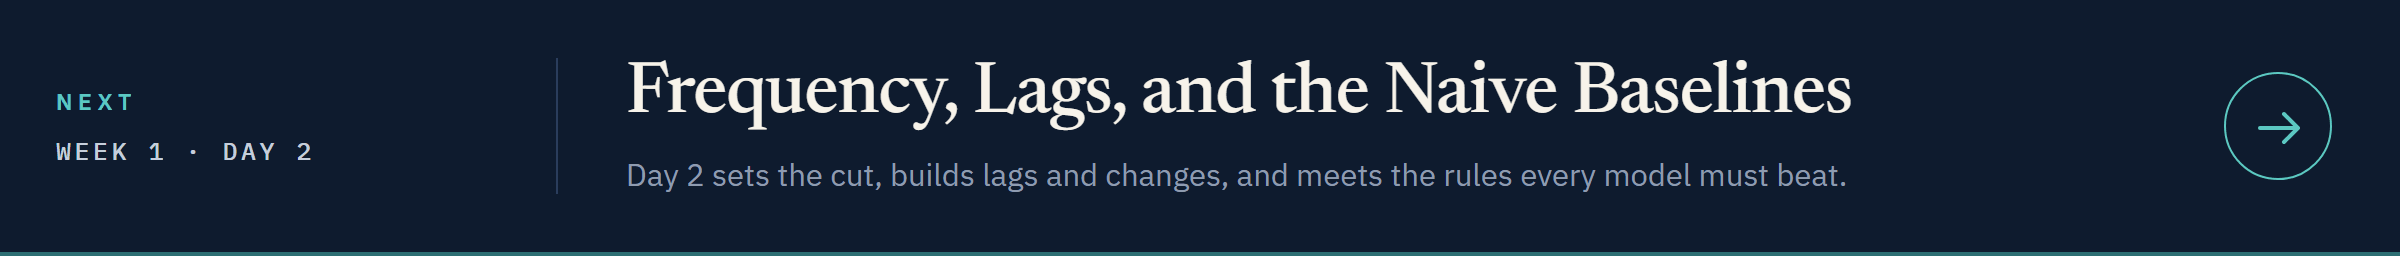](../day2/02_frequency_lags_and_the_naive_baselines.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week1/day2/02_frequency_lags_and_the_naive_baselines.ipynb)